<a href="https://colab.research.google.com/github/Nageshwar9784/MTech-AI-Data-Science/blob/main/MNIST_GPU_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Tue Nov 17 10:19:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P0             28W /   70W |     425MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch

print("PyTorch Version:", torch.__version__)

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

PyTorch Version: 2.14.1+cu130
CUDA Available: True
GPU Name: Tesla T4
GPU Memory: 14.56 GB


In [ ]:

import torch
import time

# Create two large matrices
A = torch.randn(5000, 5000)
B = torch.randn(5000, 5000)

# CPU computation
start = time.time()
C = torch.matmul(A, B)
cpu_time = time.time() - start

# GPU computation
A_gpu = A.to("cuda")
B_gpu = B.to("cuda")

torch.cuda.synchronize()
start = time.time()

C_gpu = torch.matmul(A_gpu, B_gpu)

torch.cuda.synchronize()
gpu_time = time.time() - start

print("CPU Time:", round(cpu_time, 4), "seconds")
print("GPU Time:", round(gpu_time, 4), "seconds")
print("GPU Speedup:", round(cpu_time/gpu_time, 2), "x")


CPU Time: 2.9681 seconds
GPU Time: 0.088 seconds
GPU Speedup: 33.71 x


In [ ]:

import torch
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_data))
print("Testing images:", len(test_data))
print("Image shape:", train_data[0][0].shape)



Training images: 60000
Testing images: 10000
Image shape: torch.Size([1, 28, 28])


In [ ]:
image, label = train_data[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Image data type:", image.dtype)

Image shape: torch.Size([1, 28, 28])
Label: 5
Image data type: torch.float32


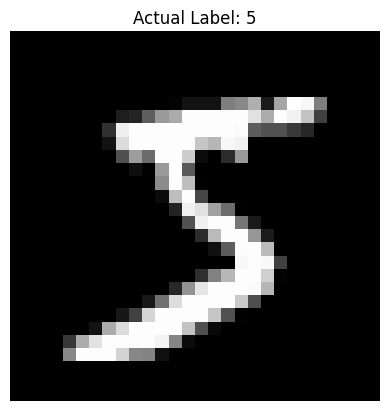

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual Label: {label}")
plt.axis("off")
plt.show()

In [ ]:
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())

print("\nFirst 5 rows and 5 columns:")
print(image[0, :5, :5])

Minimum pixel value: 0.0
Maximum pixel value: 1.0

First 5 rows and 5 columns:
tensor([[0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.]])


In [ ]:
image, label = train_data[0]

flattened_image = image.view(-1)

print("Original shape:", image.shape)
print("Flattened shape:", flattened_image.shape)
print("Total pixel values:", flattened_image.numel())

Original shape: torch.Size([1, 28, 28])
Flattened shape: torch.Size([784])
Total pixel values: 784


In [ ]:
import torch
import torch.nn as nn

class MNISTModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(784, 128)
        self.relu = nn.ReLU()
        self.layer2 = nn.Linear(128, 10)

    def forward(self, x):
        x = x.view(-1, 784)

        x = self.layer1(x)
        x = self.relu(x)
        x = self.layer2(x)

        return x

In [26]:

# Get one image from MNIST dataset
image, label = train_data[0]

# Add batch dimension
input_image = image.unsqueeze(0)

# Forward pass
model.eval()

with torch.no_grad():
    output = model(input_image)

print("Output shape:", output.shape)
print("Label:", label)


Output shape: torch.Size([1, 10])
Label: 5


In [27]:
loss_function = nn.CrossEntropyLoss()

loss = loss_function(output, torch.tensor([label]))

print("Loss:", loss.item())

Loss: 2.29205584526062


In [ ]:
model = MNISTModel()

print(model)

MNISTModel(
  (layer1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (layer2): Linear(in_features=128, out_features=10, bias=True)
)


In [28]:
probabilities = torch.softmax(output, dim=1)

print(probabilities)
print("Probability sum:", probabilities.sum().item())

tensor([[0.1037, 0.0979, 0.1137, 0.0872, 0.1039, 0.1011, 0.0933, 0.0982, 0.1187,
         0.0824]])
Probability sum: 1.0000001192092896


In [29]:
# Clear old gradients
model.zero_grad()

# Calculate loss
loss = loss_function(output, torch.tensor([label]))

# Calculate gradients
loss.backward()

RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

In [30]:
loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

print("Loss function:", loss_function)
print("Optimizer:", optimizer)


Loss function: CrossEntropyLoss()
Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


In [31]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=64,
    shuffle=False
)

In [32]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("First 10 labels:", labels[:10])

Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])
First 10 labels: tensor([5, 3, 9, 5, 0, 5, 9, 2, 0, 6])


In [33]:
model.train()

total_loss = 0

for images, labels in train_loader:

    # 1. Clear previous gradients
    optimizer.zero_grad()

    # 2. Forward propagation
    outputs = model(images)

    # 3. Calculate loss
    loss = loss_function(outputs, labels)

    # 4. Backpropagation
    loss.backward()

    # 5. Update weights
    optimizer.step()

    total_loss += loss.item()

average_loss = total_loss / len(train_loader)

print("Average Training Loss:", average_loss)

Average Training Loss: 1.2591227643461878


In [34]:

model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images)

        predicted = outputs.argmax(dim=1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print("Correct Predictions:", correct)
print("Total Images:", total)
print("Test Accuracy:", accuracy, "%")


Correct Predictions: 8650
Total Images: 10000
Test Accuracy: 86.5 %


In [35]:

for epoch in range(5):

    model.train()
    total_loss = 0

    for images, labels in train_loader:

        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_function(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(f"Epoch {epoch + 1}, Loss: {average_loss:.4f}")


Epoch 1, Loss: 0.4979
Epoch 2, Loss: 0.3928
Epoch 3, Loss: 0.3511
Epoch 4, Loss: 0.3258
Epoch 5, Loss: 0.3075


In [37]:

model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images)
        predicted = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print("Correct Predictions:", correct)
print("Total Images:", total)
print("New Test Accuracy:", accuracy, "%")


Correct Predictions: 9194
Total Images: 10000
New Test Accuracy: 91.94 %


In [38]:

model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in train_loader:

        outputs = model(images)

        predicted = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

train_accuracy = 100 * correct / total

print("Training Accuracy:", train_accuracy, "%")


Training Accuracy: 91.575 %


In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

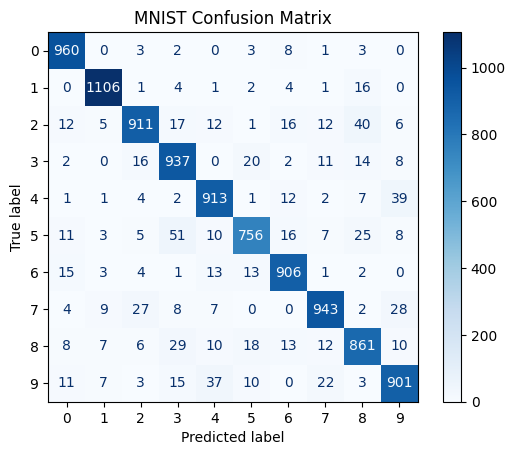

In [40]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images)
        predicted = outputs.argmax(dim=1)

        all_predictions.extend(predicted.numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

display.plot(cmap="Blues")
plt.title("MNIST Confusion Matrix")
plt.show()

In [41]:

import numpy as np

# Copy diagonal values and remove them
mistakes = cm.copy()
np.fill_diagonal(mistakes, 0)

# Find the largest misclassification
actual_digit, predicted_digit = np.unravel_index(
    np.argmax(mistakes), mistakes.shape
)

print("Most confused actual digit:", actual_digit)
print("Predicted as:", predicted_digit)
print("Number of mistakes:", mistakes[actual_digit, predicted_digit])


Most confused actual digit: 5
Predicted as: 3
Number of mistakes: 51


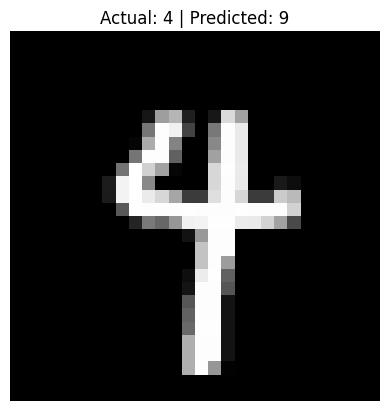

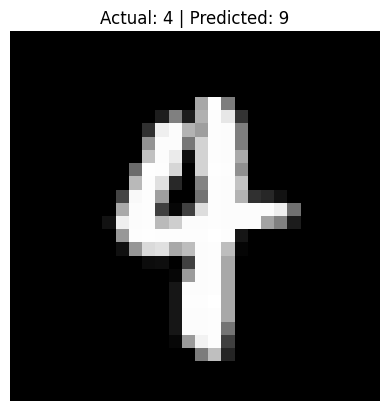

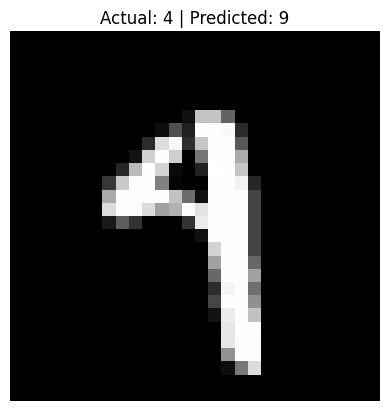

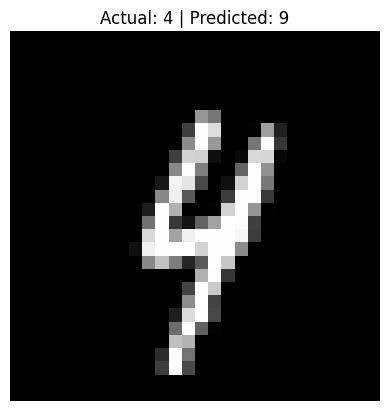

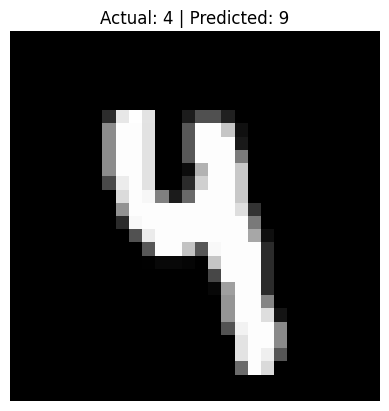

In [42]:

import matplotlib.pyplot as plt

model.eval()

shown = 0

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        for i in range(len(labels)):

            if labels[i].item() == 4 and predictions[i].item() == 9:

                plt.imshow(images[i].squeeze(), cmap="gray")
                plt.title("Actual: 4 | Predicted: 9")
                plt.axis("off")
                plt.show()

                shown += 1

            if shown == 5:
                break

        if shown == 5:
            break


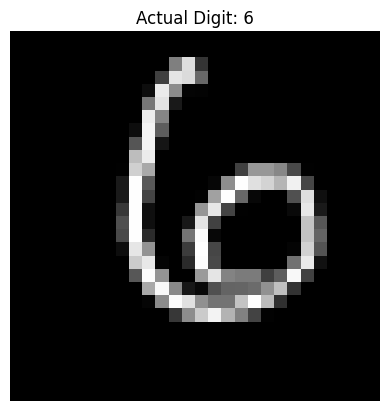

In [43]:

image, actual_label = test_data[100]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual Digit: {actual_label}")
plt.axis("off")
plt.show()


In [44]:

model.eval()

with torch.no_grad():

    input_image = image.unsqueeze(0)

    output = model(input_image)

    predicted_digit = output.argmax(dim=1).item()

print("Actual Digit:", actual_label)
print("Predicted Digit:", predicted_digit)

probabilities = torch.softmax(output, dim=1)

confidence = probabilities.max().item() * 100

print("Predicted Digit:", predicted_digit)
print("Confidence:", round(confidence, 2), "%")


Actual Digit: 6
Predicted Digit: 6
Predicted Digit: 6
Confidence: 93.0 %


In [47]:

from google.colab import files

uploaded = files.upload()

print("Uploaded file:", list(uploaded.keys())[0])


Saving 4image.jpeg to 4image.jpeg
Uploaded file: 4image.jpeg


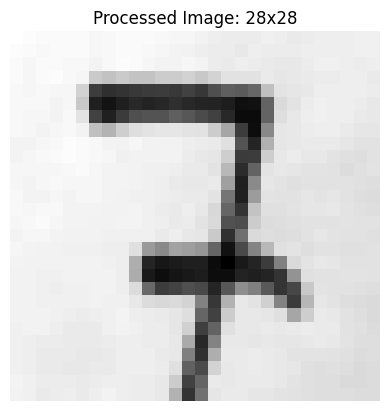

Input shape: torch.Size([1, 28, 28])


In [63]:

from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt

# Uploaded image filename
image_path = "7im.jpg"

# Open image and convert to grayscale
custom_image = Image.open(image_path).convert("L")

# Resize image to 28x28
resize_transform = transforms.Resize((28, 28))

# Convert image into tensor
to_tensor = transforms.ToTensor()

input_tensor = to_tensor(resize_transform(custom_image))

# Display processed image
plt.imshow(input_tensor.squeeze(), cmap="gray")
plt.title("Processed Image: 28x28")
plt.axis("off")
plt.show()

print("Input shape:", input_tensor.shape)


Minimum pixel: 0.2078431397676468
Maximum pixel: 0.7137255072593689


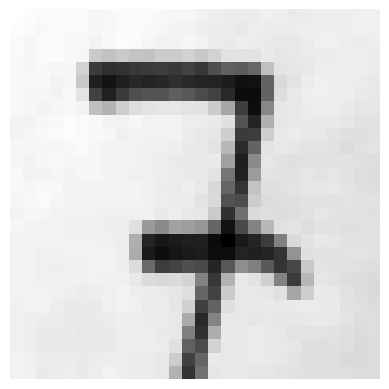

In [64]:

print("Minimum pixel:", input_tensor.min().item())
print("Maximum pixel:", input_tensor.max().item())

plt.imshow(input_tensor.squeeze(), cmap="gray")
plt.axis("off")
plt.show()


In [74]:

# Invert image
input_tensor = 1 - input_tensor

# Add batch dimension
input_tensor = input_tensor.unsqueeze(0)

# Predict
model.eval()

with torch.no_grad():
    output = model(input_tensor)

    probabilities = torch.softmax(output, dim=1)

    predicted_digit = output.argmax(dim=1).item()

    confidence = probabilities.max().item() * 100

print("Predicted Digit:", predicted_digit)
print("Confidence:", round(confidence, 2), "%")


Predicted Digit: 5
Confidence: 59.87 %


Image shape: torch.Size([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 28, 28])
Minimum: 0.2078431248664856
Maximum: 0.7137255072593689


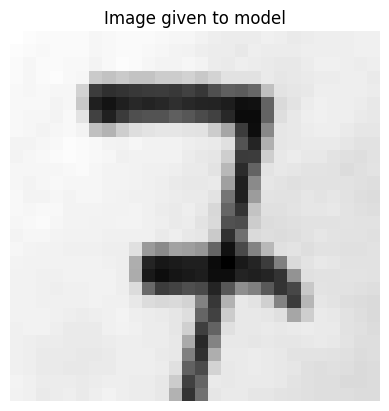

In [75]:

print("Image shape:", input_tensor.shape)
print("Minimum:", input_tensor.min().item())
print("Maximum:", input_tensor.max().item())

plt.imshow(input_tensor.squeeze().cpu(), cmap="gray")
plt.title("Image given to model")
plt.axis("off")
plt.show()


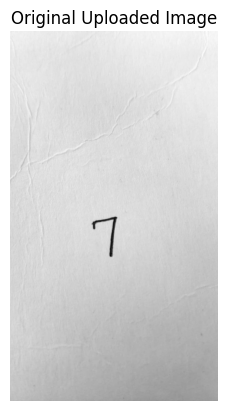

In [95]:

from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import numpy as np

image_path = "7img.jpeg"  # Apna filename likho

img = Image.open(image_path).convert("L")

plt.imshow(img, cmap="gray")
plt.title("Original Uploaded Image")
plt.axis("off")
plt.show()


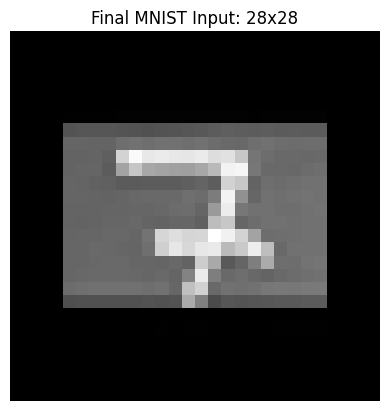

Tensor shape: torch.Size([1, 1, 28, 28])


In [78]:

# True: original image has white background and black digit
# False: original image has black background and white digit

white_background = True

if white_background:
    img = ImageOps.invert(img)

# Find digit boundaries
mask = img.point(lambda p: 255 if p > 30 else 0)
bbox = mask.getbbox()

if bbox is None:
    raise ValueError("Digit not detected. Check your image.")

# Crop digit
digit = img.crop(bbox)

# Make square while preserving proportions
width, height = digit.size
side = max(width, height)

square = Image.new("L", (side, side), 0)
square.paste(digit, ((side-width)//2, (side-height)//2))

# Resize digit to 20x20
digit = square.resize((20, 20), Image.Resampling.LANCZOS)

# Place digit at center of 28x28 black canvas
canvas = Image.new("L", (28, 28), 0)
canvas.paste(digit, (4, 4))

# Convert to PyTorch tensor
input_tensor = transforms.ToTensor()(canvas).unsqueeze(0)

# Display final processed image
plt.imshow(canvas, cmap="gray")
plt.title("Final MNIST Input: 28x28")
plt.axis("off")
plt.show()

print("Tensor shape:", input_tensor.shape)


In [98]:

model.eval()

with torch.no_grad():
    output = model(input_tensor)
    probabilities = torch.softmax(output, dim=1)

    predicted_digit = output.argmax(dim=1).item()
    confidence = probabilities.max().item() * 100

print("Predicted Digit:", predicted_digit)
print("Confidence:", round(confidence, 2), "%")


Predicted Digit: 4
Confidence: 27.8 %


In [99]:

for digit, probability in enumerate(probabilities[0]):
    print(f"Digit {digit}: {probability.item()*100:.2f}%")


Digit 0: 0.56%
Digit 1: 0.07%
Digit 2: 6.94%
Digit 3: 1.63%
Digit 4: 27.80%
Digit 5: 1.86%
Digit 6: 2.38%
Digit 7: 23.74%
Digit 8: 11.21%
Digit 9: 23.81%


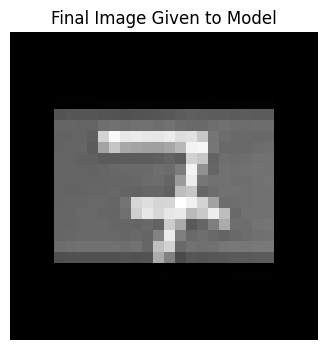

In [100]:

plt.figure(figsize=(4, 4))
plt.imshow(canvas, cmap="gray")
plt.title("Final Image Given to Model")
plt.axis("off")
plt.show()


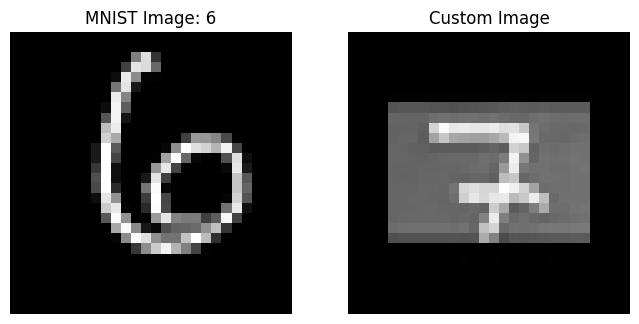

In [101]:

# Original MNIST image
mnist_image, mnist_label = test_data[100]

# Custom processed image
custom = input_tensor.squeeze().cpu()

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(mnist_image.squeeze(), cmap="gray")
plt.title(f"MNIST Image: {mnist_label}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(custom, cmap="gray")
plt.title("Custom Image")
plt.axis("off")

plt.show()


In [87]:

print("MNIST image:")
print("Mean:", mnist_image.mean().item())
print("Max:", mnist_image.max().item())

print("\nCustom image:")
print("Mean:", custom.mean().item())
print("Max:", custom.max().item())


MNIST image:
Mean: 0.09088636189699173
Max: 1.0

Custom image:
Mean: 0.13391856849193573
Max: 0.7803921699523926


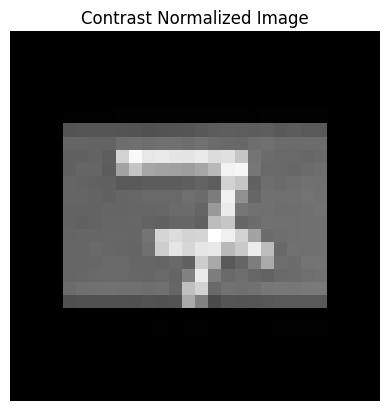

Shape: torch.Size([1, 1, 28, 28])
Maximum: 1.0


In [88]:

# Convert custom image into numpy array
custom_array = np.array(canvas).astype(np.float32)

# Find minimum and maximum pixel values
pixel_min = custom_array.min()
pixel_max = custom_array.max()

# Contrast normalization
if pixel_max > pixel_min:
    normalized_array = (
        (custom_array - pixel_min) /
        (pixel_max - pixel_min)
    )

# Convert back to image
normalized_image = Image.fromarray(
    (normalized_array * 255).astype(np.uint8)
)

# Convert into tensor
normalized_tensor = transforms.ToTensor()(
    normalized_image
).unsqueeze(0)

# Display
plt.imshow(normalized_image, cmap="gray")
plt.title("Contrast Normalized Image")
plt.axis("off")
plt.show()

print("Shape:", normalized_tensor.shape)
print("Maximum:", normalized_tensor.max().item())


In [89]:

model.eval()

with torch.no_grad():
    new_output = model(normalized_tensor)

    new_probabilities = torch.softmax(new_output, dim=1)

    new_prediction = new_output.argmax(dim=1).item()

    new_confidence = new_probabilities.max().item() * 100

print("New Prediction:", new_prediction)
print("New Confidence:", round(new_confidence, 2), "%")


New Prediction: 4
New Confidence: 29.9 %


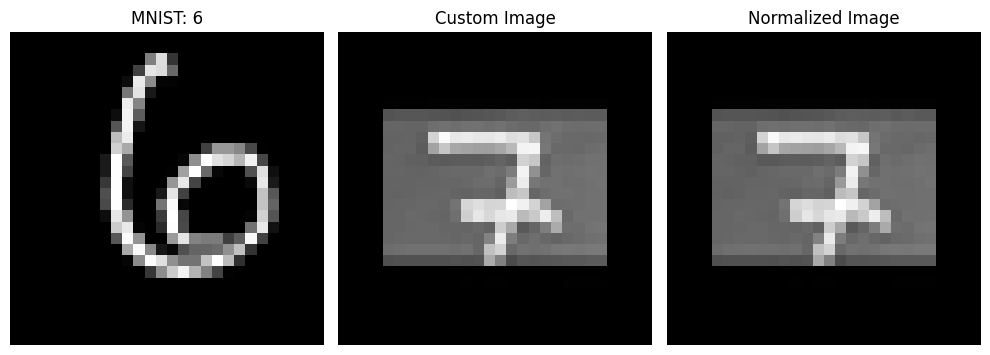

In [90]:

fig, axes = plt.subplots(1, 3, figsize=(10, 4))

# Original MNIST image
axes[0].imshow(mnist_image.squeeze(), cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"MNIST: {mnist_label}")

# Original custom processed image
axes[1].imshow(canvas, cmap="gray")
axes[1].set_title("Custom Image")

# Contrast normalized image
axes[2].imshow(normalized_image, cmap="gray")
axes[2].set_title("Normalized Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


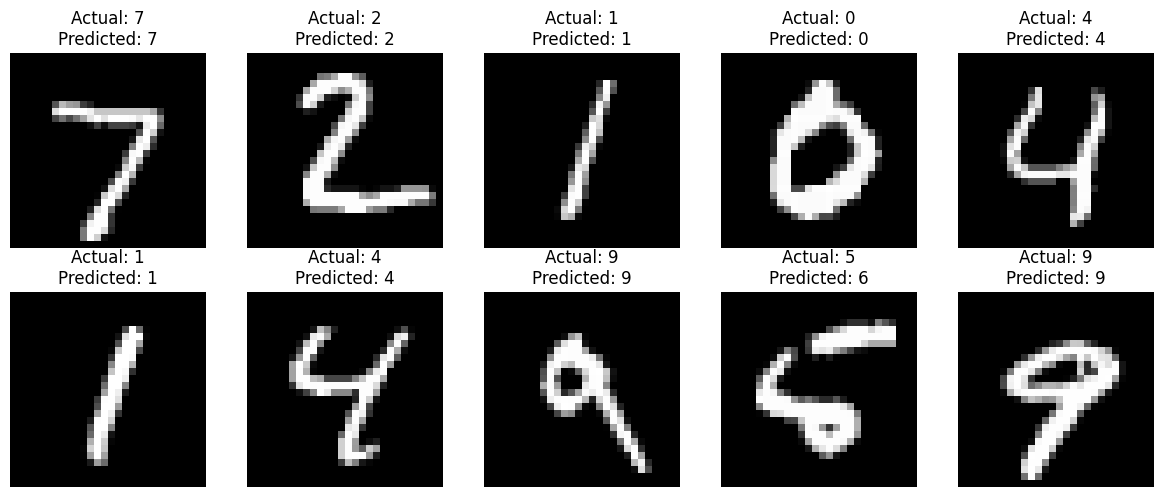

In [91]:

# Select 10 test images
images, labels = next(iter(test_loader))

model.eval()

with torch.no_grad():
    outputs = model(images)
    predictions = outputs.argmax(dim=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(
        f"Actual: {labels[i].item()}\nPredicted: {predictions[i].item()}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()



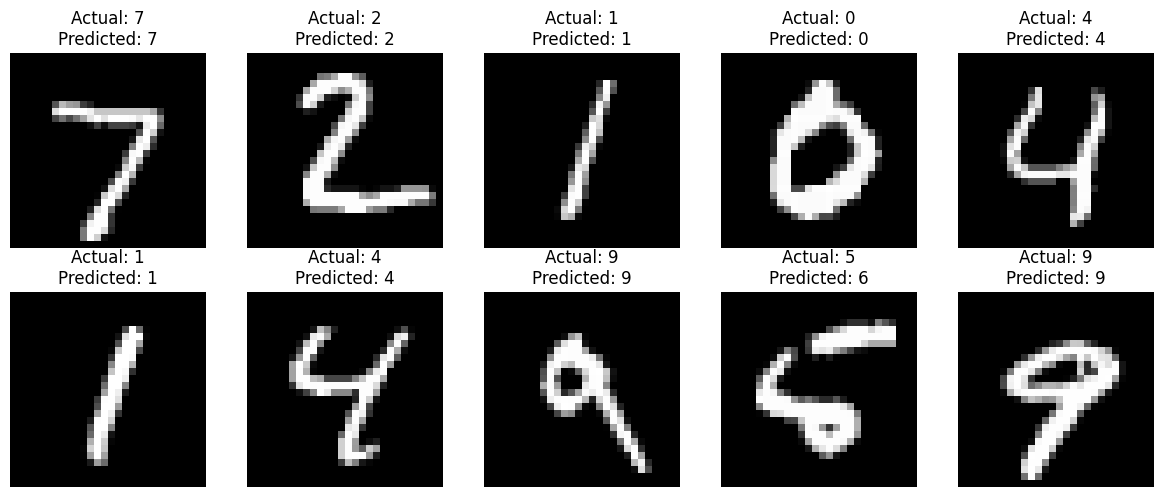

In [92]:

images, labels = next(iter(test_loader))

model.eval()

with torch.no_grad():
    outputs = model(images)
    predictions = outputs.argmax(dim=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].squeeze(), cmap="gray")

    plt.title(
        f"Actual: {labels[i].item()}\nPredicted: {predictions[i].item()}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


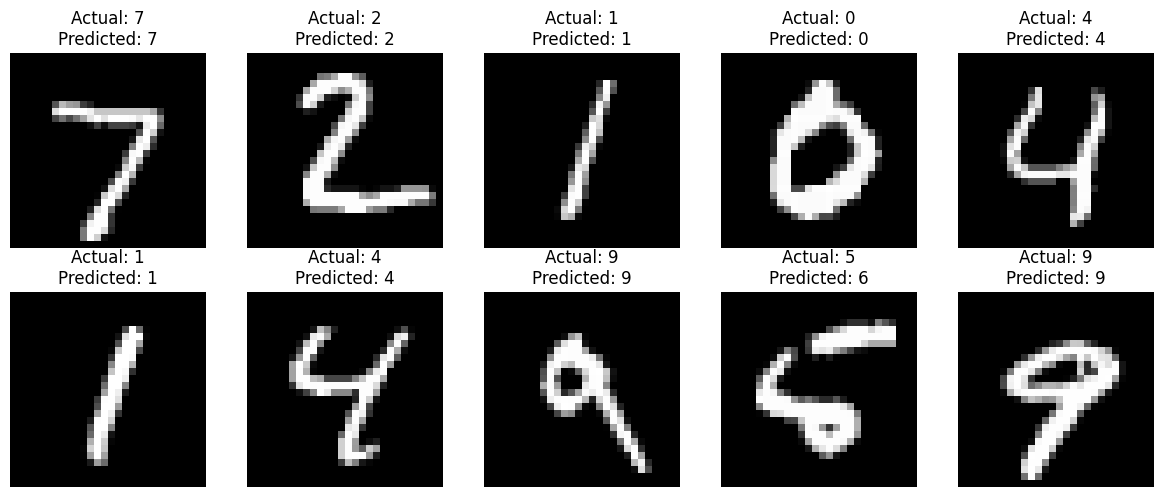

In [93]:

images, labels = next(iter(test_loader))

model.eval()

with torch.no_grad():
    outputs = model(images)
    predictions = outputs.argmax(dim=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].squeeze(), cmap="gray")

    plt.title(
        f"Actual: {labels[i].item()}\nPredicted: {predictions[i].item()}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


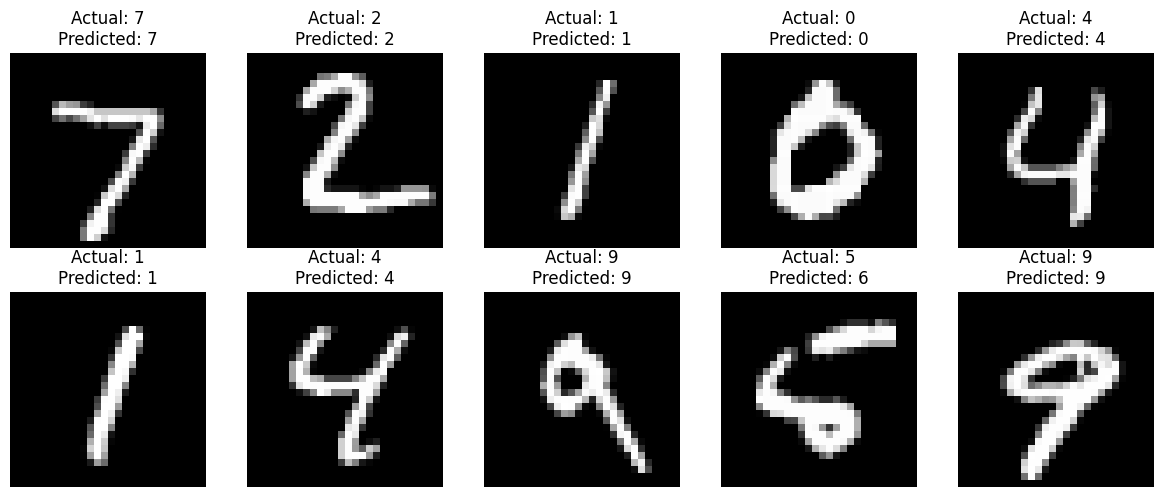

In [102]:

# Select 10 test images
images, labels = next(iter(test_loader))

model.eval()

with torch.no_grad():
    outputs = model(images)
    predictions = outputs.argmax(dim=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(
        f"Actual: {labels[i].item()}\nPredicted: {predictions[i].item()}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


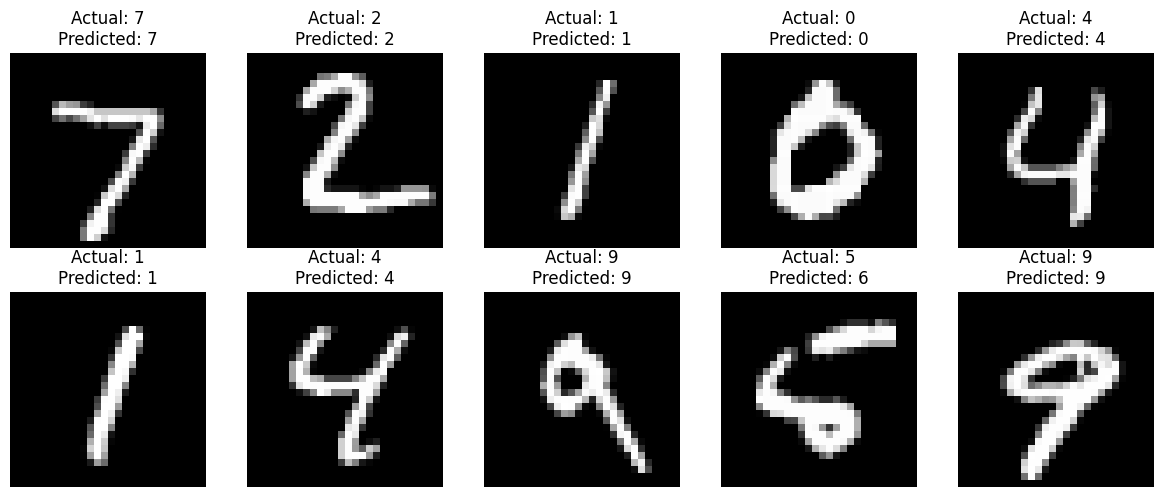

In [103]:

images, labels = next(iter(test_loader))

model.eval()

with torch.no_grad():
    outputs = model(images)
    predictions = outputs.argmax(dim=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].squeeze(), cmap="gray")

    plt.title(
        f"Actual: {labels[i].item()}\nPredicted: {predictions[i].item()}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()
